
# Neural Networks 101

## Fundamentals

For this example we are going to use the classic example of a number classifier, which takes in 784 inputs from a 28x28 pixel space and outputs an answer from 0-9. We are going to start by defining the mathematical terms.

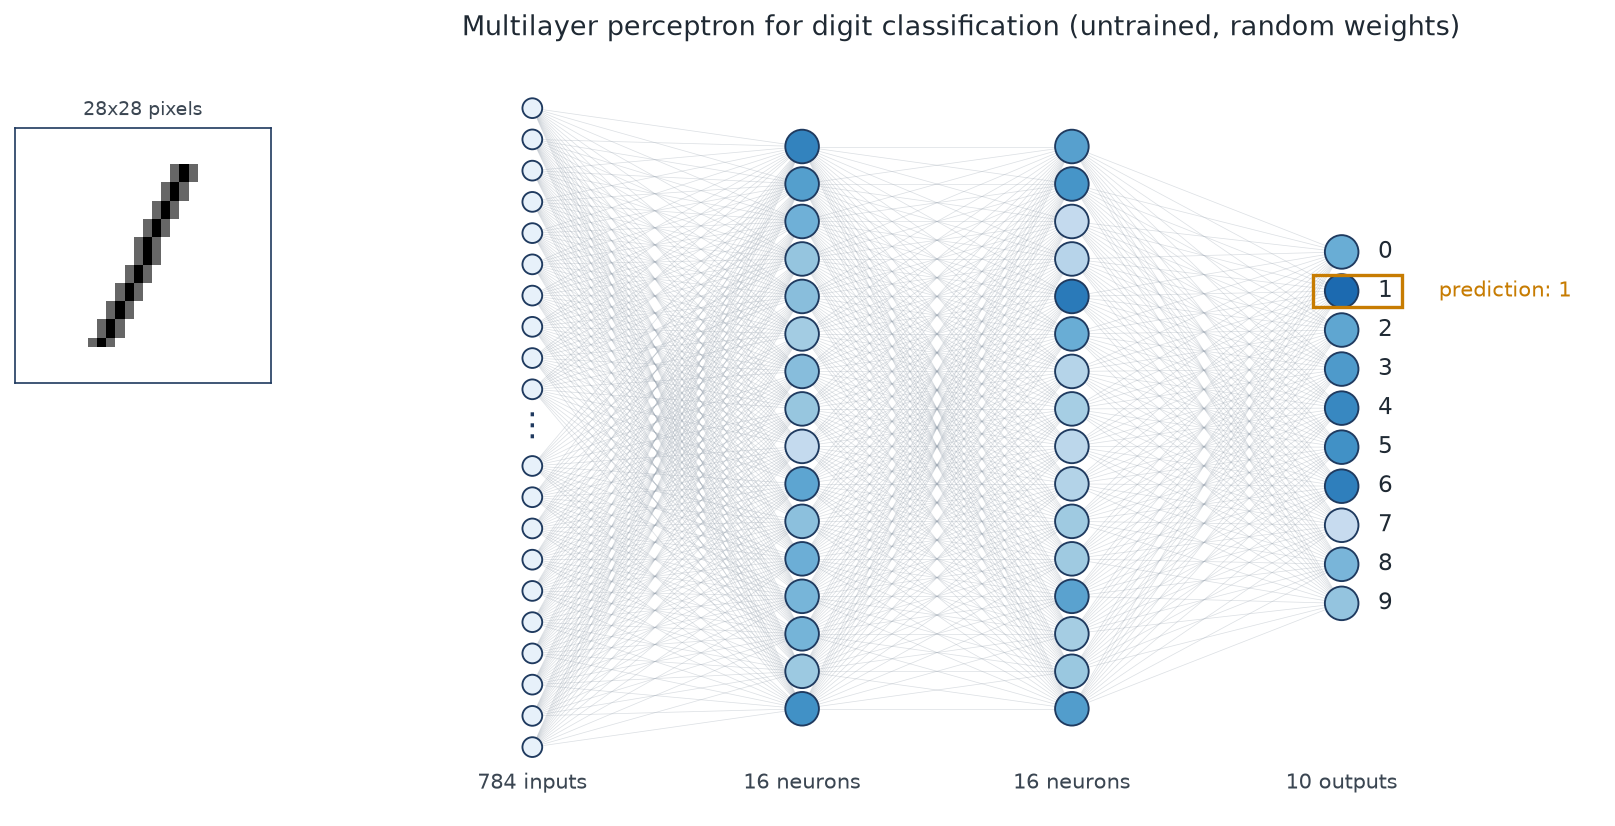

We will be using this example from the 3Blue1Brown channel. https://www.youtube.com/watch?v=aircAruvnKk&list=PLZHQObOWTQDN52m7Y21ePrTbvXkPaWVSg

## Neurons and layers

Each neuron has an activation value $a$ from 0 to 1.
Layer 1 is our 784 input neurons, layers 2 and 3 are our hidden middle layers with 16 neurons each (an arbitrary choice for this example), and our 4th answer layer has 10 answer neurons.

The highest value of $a$ in layer 4 is the answer given by the neural network, given the 784 input values.

## Weights

The weights ($w$) are the multipliers that determine how much the magnitude of $a_1$ affects the value of the neuron in the following layer.

And so the value of a neuron in layer 2 is determined by the sum of all activations multiplied by their individual weights. As this can result in a value outside of 0 to 1, we wrap the function in a sigmoid function, so we keep all $a$ values between 0 and 1.


## The activation function

For a single neuron in the next layer:

$$
a^{(1)} = \sigma\left(w_1 a_1 + w_2 a_2 + w_3 a_3 + \cdots + w_n a_n\right) = \sigma\left(\sum_{i=1}^{n} w_i a_i\right)
$$

where the sigmoid function is:

$$
\sigma(x) = \frac{1}{1 + e^{-x}}
$$

 The final term in this fundamental function is the bias ($b$). It is added to the weighted sum before it is passed through the sigmoid function, and shifts the result up or down. This changes how large the weighted sum needs to be before the neuron activates, so each neuron has its own threshold. Like the weights, the bias is not chosen by hand. It is learned during training.

 Full equation:

  $$a^{(1)} = \sigma\left(\sum_{i=1}^{n} w_i a_i + b\right)$$



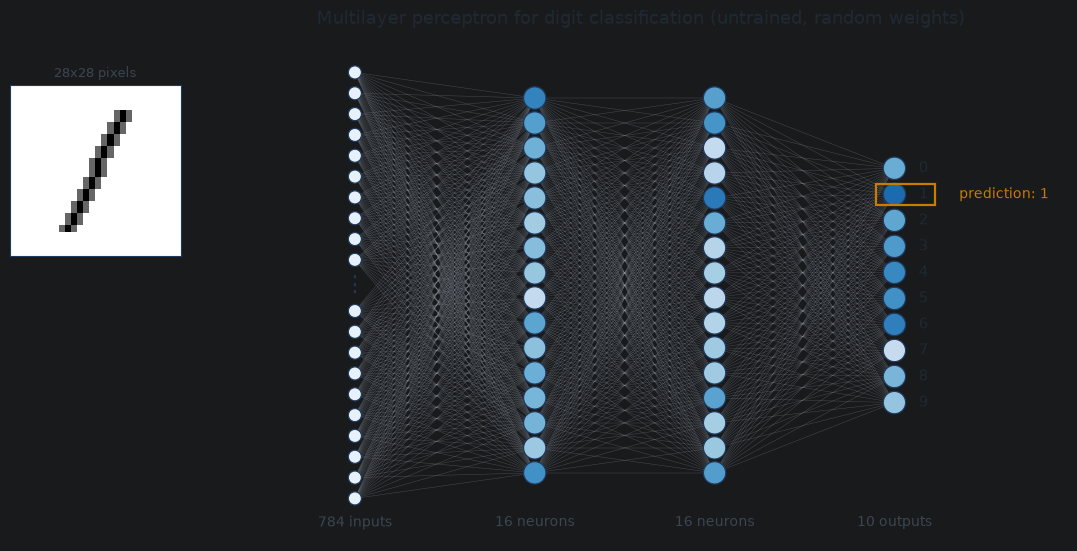

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def make_digit_one(size=28):
    """A synthetic slanted '1' on a 28x28 grid, values 0 to 1."""
    img = np.zeros((size, size))
    for r in range(4, 24):
        c = int(round(18 - (r - 4) * 0.45))
        img[r, c] = 1.0
        img[r, c - 1] = 0.6
        img[r, c + 1] = 0.6
    return img


def forward(x, layer_sizes, seed=0):
    """Forward pass through a randomly initialised sigmoid network. Returns activations per layer."""
    rng = np.random.default_rng(seed)
    acts = [x]
    a = x
    for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
        W = rng.normal(0, 1 / np.sqrt(n_in), size=(n_out, n_in))
        b = rng.normal(0, 0.5, size=n_out)
        a = sigmoid(W @ a + b)
        acts.append(a)
    return acts


def plot_mlp(layer_sizes=(784, 16, 16, 10), activations=None, input_image=None,
             input_shown=20, output_labels=None, title=None, ax=None):
    """Draw a multilayer perceptron. The first layer is abbreviated to `input_shown` neurons
    with an ellipsis. Neuron fill shows activation (0 = light, 1 = dark)."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 6.5))
    else:
        fig = ax.figure
    cmap = plt.get_cmap("Blues")
    edge_col = "#1F3A5F"
    line_col = "#9AA5B1"
    n_layers = len(layer_sizes)
    xs = np.linspace(0, 1, n_layers)

    # y positions per layer; the input layer shows the top and bottom halves with a gap
    ys, shown_idx = [], []
    for li, n in enumerate(layer_sizes):
        if li == 0 and n > input_shown:
            half = input_shown // 2
            top = np.linspace(1, 0.12, half)
            bot = np.linspace(-0.12, -1, half)
            ys.append(np.concatenate([top, bot]))
            shown_idx.append(list(range(half)) + list(range(n - half, n)))
        else:
            span = min(1.0, 0.055 * n)
            ys.append(np.linspace(span, -span, n))
            shown_idx.append(list(range(n)))

    # edges
    for li in range(n_layers - 1):
        for y0 in ys[li]:
            for y1 in ys[li + 1]:
                ax.plot([xs[li], xs[li + 1]], [y0, y1], color=line_col, lw=0.35, alpha=0.35, zorder=1)

    # neurons
    for li, n in enumerate(layer_sizes):
        if activations is not None:
            vals = np.asarray(activations[li])[shown_idx[li]]
        else:
            vals = np.zeros(len(shown_idx[li]))
        cols = cmap(0.08 + 0.82 * np.clip(vals, 0, 1))
        size = 90 if li == 0 else 260
        ax.scatter(np.full(len(ys[li]), xs[li]), ys[li], s=size, c=cols,
                   edgecolors=edge_col, linewidths=0.9, zorder=3)

    # input ellipsis and count
    if layer_sizes[0] > input_shown:
        ax.text(xs[0], 0, "⋮", ha="center", va="center", fontsize=16, color=edge_col)
        ax.annotate(f"{layer_sizes[0]} inputs", xy=(xs[0], -1.08), ha="center", va="top",
                    fontsize=10, color="#3B4652")
    for li in range(1, n_layers - 1):
        ax.text(xs[li], -1.08, f"{layer_sizes[li]} neurons", ha="center", va="top",
                fontsize=10, color="#3B4652")
    ax.text(xs[-1], -1.08, f"{layer_sizes[-1]} outputs", ha="center", va="top",
            fontsize=10, color="#3B4652")

    # output labels and the winner
    if output_labels is None:
        output_labels = [str(i) for i in range(layer_sizes[-1])]
    for lab, y in zip(output_labels, ys[-1]):
        ax.text(xs[-1] + 0.045, y, lab, va="center", ha="left", fontsize=11, color="#1F2933")
    if activations is not None:
        k = int(np.argmax(activations[-1]))
        y = ys[-1][k]
        ax.add_patch(Rectangle((xs[-1] - 0.035, y - 0.05), 0.11, 0.1, fill=False,
                               edgecolor="#C77C02", lw=1.6, zorder=4))
        ax.text(xs[-1] + 0.12, y, f"prediction: {output_labels[k]}", va="center",
                fontsize=10, color="#C77C02")

    # input image inset
    if input_image is not None:
        inset = ax.inset_axes([-0.24, 0.56, 0.2, 0.36])
        inset.imshow(input_image, cmap="gray_r", vmin=0, vmax=1)
        inset.set_xticks([]); inset.set_yticks([])
        for s in inset.spines.values():
            s.set_edgecolor(edge_col)
        inset.set_title(f"{input_image.shape[0]}x{input_image.shape[1]} pixels", fontsize=9, color="#3B4652")

    ax.set_xlim(-0.26 if input_image is not None else -0.1, 1.32)
    ax.set_ylim(-1.2, 1.15)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=13, color="#1F2933", pad=12)
    return fig, ax


# Draw the network with a synthetic digit fed through random, untrained weights
img = make_digit_one()
acts = forward(img.flatten(), (784, 16, 16, 10), seed=0)
fig, ax = plot_mlp((784, 16, 16, 10), activations=acts, input_image=img,
                   title="Multilayer perceptron for digit classification (untrained, random weights)")
fig.savefig("images/mlp_architecture.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()